# QRT data and ablation experiments

Study the sharing rules between different objects, local corrections and the complementarity of CatBoost and GRU. This notebook embeds summary statistics and pictures of historical experiments and does not rely on intermediate models, prediction files, or analysis directories. The table and image output are saved for direct reading on GitHub; running the cell does not start training. See [summary.md](summary.md) for the research conclusion, and see [README.md](README.md) for the implementation method.

In [1]:
from io import StringIO
import json
import pandas as pd
from IPython.display import display

# Historical aggregate results, embedded for a self-contained presentation.
SAVED_TABLES = {'architecture_comparison.csv': 'family,structure,accuracy,kind,source,column,n\nCatBoost,Global standalone,0.5217095165185847,Historical architecture comparison,model_catboost_global/oof_predictions.csv,score_mean,527073\nCatBoost,Global base (paired),0.5205237225204099,Paired branch comparison,model_catboost_enhance_residual/oof_predictions_residual.csv,global_score,527073\nCatBoost,Global + group residual (paired),0.5183817042421068,Paired branch comparison,model_catboost_enhance_residual/oof_predictions_residual.csv,final_score,527073\nCatBoost,Global regression base v2,0.5203491736438786,Paired branch comparison,model_catboost_enhance2/oof_predictions.csv,global_score,527073\nCatBoost,Global + group residual v2,0.5175905424865246,Paired branch comparison,model_catboost_enhance2/oof_predictions.csv,score_mean,527073\nCatBoost,Allocation independent,0.5161656924183178,Historical architecture comparison,model_catboost_allocation_5fold/oof_predictions.csv,score_mean,527073\nCatBoost,Allocation + shape,0.5166760581551322,Historical architecture comparison,model_catboost_allocation_shape_features/oof_predictions.csv,score_mean,527073\nCatBoost,Group base,,Saved OOF unavailable,model_catboost_group_allocation_residual/oof_predictions.csv,base_score_mean,0\nCatBoost,Group + allocation residual,,Saved OOF unavailable,model_catboost_group_allocation_residual/oof_predictions.csv,final_score_mean,0\nCatBoost,Cluster base,0.5217190028705702,Paired branch comparison,model_catboost_cluster_allocation_residual/oof_predictions.csv,base_score_mean,527073\nCatBoost,Cluster + allocation residual,0.5207912376463981,Paired branch comparison,model_catboost_cluster_allocation_residual/oof_predictions.csv,final_score_mean,527073\nGRU,Group independent (seed42),0.5226353844723596,Historical architecture comparison,model_catboost_gru_blend/oof_aligned.csv,gru_score,527073\nGRU,Global head (group model),0.5235498688037521,Paired branch comparison,model_gru_global/oof_predictions.csv,base_logit_mean,527073\nGRU,Global + group residual,0.5248457044849575,Paired branch comparison,model_gru_global/oof_predictions.csv,final_logit_mean,527073\nGRU,Global head (final base run),0.5244036404824379,Paired branch comparison,model_gru_global_cluster_residual/global_base/oof_predictions.csv,base_logit_mean,527073\nGRU,Global + group (final base run),0.5257431133827762,Paired branch comparison,model_gru_global_cluster_residual/global_base/oof_predictions.csv,final_logit_mean,527073\nGRU,Global + group + cluster residual,0.5267012349333015,Historical architecture comparison,model_gru_global_cluster_residual/oof_predictions.csv,final_logit,527073\nGRU,Group base,,Saved OOF unavailable,model_gru_group_allocation_residual/oof_predictions.csv,base_score_mean,0\nGRU,Group + allocation residual,,Saved OOF unavailable,model_gru_group_allocation_residual/oof_predictions.csv,final_score_mean,0\nGRU,Cluster base v3,0.5056548144184961,Paired branch comparison,model_gru_cluster_allocation_residual_v3/oof_predictions.csv,base_score_mean,527073\nGRU,Cluster + allocation residual v3,0.5063757771693864,Paired branch comparison,model_gru_cluster_allocation_residual_v3/oof_predictions.csv,final_score_mean,527073\nCombined,CatBoost final zscore,0.5203036391543486,Blend comparison on the same OOF,model_catboost_gru_segmented_linear_blend/oof_predictions.csv,catboost_z,527073\nCombined,GRU final zscore,0.5264261307257249,Blend comparison on the same OOF,model_catboost_gru_segmented_linear_blend/oof_predictions.csv,gru_z,527073\nCombined,Cluster linear blend,0.5251151168813428,Blend comparison on the same OOF,model_catboost_gru_segmented_linear_blend/oof_predictions.csv,cluster_blend_score,527073\nCombined,Allocation linear blend,0.5283556547195549,Blend comparison on the same OOF,model_catboost_gru_segmented_linear_blend/oof_predictions.csv,allocation_blend_score,527073\n', 'saved_component_ablation.csv': 'variant,accuracy,delta_pp,delta_ci_low_pp,delta_ci_high_pp,correct_to_wrong,wrong_to_correct\nFull allocation blend,0.5283556547195549,0.0,0.0,0.0,0,0\nRemove CatBoost residual,0.5242461670394803,-0.41094876800746766,-0.5652571751464064,-0.2502937786985569,50062,47896\nRemove GRU residual,0.5262364036860169,-0.2119251033538049,-0.26302196215640544,-0.16060053031158725,7827,6710\nRemove both residuals,0.5239634737503154,-0.43921809692395547,-0.5979785194696612,-0.2733677464112455,51331,49016\nRemove CatBoost branch,0.5264261307257249,-0.19295239938300768,-0.37381619778708286,-0.014347209341517373,51791,50774\nRemove GRU branch,0.5203036391543486,-0.8052015565206337,-0.9120831472655967,-0.687983740645873,28007,23763\nEqual weights,0.5257582915459529,-0.25973631736021385,-0.34977339342691105,-0.15797791024344246,21804,20435\nCluster weights,0.5251151168813428,-0.3240537838212164,-0.3985417763228757,-0.25442467030900096,13912,12204\nGlobal tuned weight,0.5250980414477691,-0.32576132717858813,-0.4011973487881096,-0.2564443295428655,13980,12263\n', 'feature_statistics.csv': ',count,mean,std,min,1%,5%,50%,95%,99%,max,missing_rate\nRET_20,527015.0,2.1333306050560336e-05,0.003101783468455188,-0.04622569,-0.00852268346,-0.00475813923,3.14234e-05,0.0047604111399999986,0.008244889589999997,0.12983996,0.00011004168303062384\nRET_19,527023.0,2.5310163283849583e-05,0.003089216594668901,-0.046986826,-0.00847058797,-0.0047493195,3.1425578e-05,0.00475610874,0.008278765659999958,0.12934314,9.486351985398607e-05\nRET_18,527031.0,2.6858469127058058e-05,0.0030818294231161774,-0.046778917,-0.0084913643,-0.004727477900000001,3.0931245e-05,0.0047410822,0.008271940100000002,0.13050291,7.96853566773483e-05\nRET_17,527039.0,2.494795451766886e-05,0.003075331210110682,-0.046368413,-0.00845476946,-0.004725804829999999,2.8894254e-05,0.004733950639999998,0.008271273699999998,0.1297121,6.450719350071053e-05\nRET_16,527047.0,2.401180345877873e-05,0.0030646981475968217,-0.046273045,-0.00842939578,-0.00472425989,3.0455001e-05,0.004727575099999999,0.008237365499999994,0.10798292,4.9329030324072756e-05\nRET_15,527055.0,2.7239718324564057e-05,0.003061120841995734,-0.046619367,-0.00839272478,-0.00470876219,3.218722e-05,0.004724017759999998,0.008212628080000003,0.12946947,3.4150867147434983e-05\nRET_14,527060.0,2.611879296895359e-05,0.0030592319394241547,-0.045872767,-0.00838608386,-0.00471474863,3.1769233e-05,0.0047101838049999996,0.008205769669999995,0.13142382,2.4664515162036378e-05\nRET_13,527064.0,2.6355498779551618e-05,0.003056117801828913,-0.046168473,-0.00836061358,-0.00470385665,3.2912841999999996e-05,0.0046981999,0.008181710909999999,0.12936214,1.7075433573717492e-05\nRET_12,527067.0,2.4179445255023427e-05,0.003059058864668945,-0.04643679,-0.008373731839999999,-0.00471127585,3.1862746e-05,0.004700790779999988,0.008193044919999996,0.12930004,1.1383622382478328e-05\nRET_11,527069.0,2.1664322324038e-05,0.0030585372363119614,-0.046217147,-0.00837056284,-0.00470899174,3.059049e-05,0.004687655199999995,0.008177350880000007,0.12941073,7.5890815883188855e-06\nRET_10,527071.0,2.3019850407118068e-05,0.0030559043901472243,-0.0462082,-0.0083578849,-0.00469627885,2.753175e-05,0.0046847895,0.008179037499999988,0.12932019,3.7945407941594427e-06\nRET_9,527073.0,2.554745004844887e-05,0.003049492058914375,-0.043436524,-0.00834103212,-0.004675373219999999,3.0300178e-05,0.004673221839999999,0.008192181259999987,0.12945583,0.0\nRET_8,527073.0,2.576568303649192e-05,0.0030467010799283822,-0.043651503,-0.00834408304,-0.004673443239999999,2.9264393e-05,0.004663887799999997,0.008185473079999983,0.12930155,0.0\nRET_7,527073.0,2.6076383143034964e-05,0.0030478698437493173,-0.044076074,-0.0083076751,-0.00467086678,3.078381e-05,0.004661203399999999,0.008180764719999975,0.12979193,0.0\nRET_6,527073.0,2.7752950040448412e-05,0.0030471598913245344,-0.043569278,-0.00829471712,-0.00468134852,3.1732805e-05,0.004669187239999998,0.008185198279999997,0.13008988,0.0\nRET_5,527073.0,3.213366849134982e-05,0.0030416135094569956,-0.04362071,-0.0082907464,-0.0046587524,3.477455e-05,0.004680623199999998,0.00820845732,0.12978724,0.0\nRET_4,527073.0,3.393644897848592e-05,0.0030513457029974845,-0.042354602,-0.00833111624,-0.00466637618,3.4801553e-05,0.0046919093999999925,0.008226260319999972,0.13114128,0.0\nRET_3,527073.0,3.847814625646026e-05,0.0030583575989412705,-0.043676026,-0.0083402774,-0.00466264302,3.7688154e-05,0.004703132539999998,0.008277286939999963,0.1297979,0.0\nRET_2,527073.0,4.2090230442321345e-05,0.0030679070768068507,-0.0437233,-0.00834312816,-0.004659127680000001,3.833803e-05,0.004706696599999999,0.008269281859999991,0.129412,0.0\nRET_1,527073.0,7.858447021902262e-05,0.003041091913956499,-0.03935147,-0.00817972768,-0.00452091704,6.229043e-05,0.004691495319999996,0.008244659179999995,0.12931393,0.0\nSIGNED_VOLUME_20,518575.0,0.24750389324854052,1.6287388207043132,-151.25533,-3.959967444,-1.91668353,0.67327523,1.99823706,3.6916916240000015,71.1931,0.016123003834383472\nSIGNED_VOLUME_19,524071.0,0.2505052628623082,1.63932380081928,-198.8339,-3.97180071,-1.92772535,0.6681988,2.0163453000000002,3.7172047999999993,85.87001,0.005695605732033324\nSIGNED_VOLUME_18,526214.0,0.2522296254230346,1.6314887018396642,-200.05112,-3.977084316,-1.94979832,0.663143585,2.0329212949999973,3.7516525579999995,64.37187,0.0016297552710914807\nSIGNED_VOLUME_17,527015.0,0.2531341523398791,1.639422179966717,-204.21906,-3.9745451719999996,-1.96364551,0.6585431,2.0509168,3.7546985719999975,65.50221,0.00011004168303062384\nSIGNED_VOLUME_16,527023.0,0.255166469000382,1.6230625932949858,-200.16425,-3.962081532,-1.9742197699999997,0.6549341,2.066718189999999,3.752249519999995,70.38797,9.486351985398607e-05\nSIGNED_VOLUME_15,527031.0,0.25577359487960116,1.6235721032581971,-188.6725,-3.9750533299999997,-1.98767355,0.6509868,2.0757396000000004,3.7615139000000015,125.0284,7.96853566773483e-05\nSIGNED_VOLUME_14,527039.0,0.25733831321370204,1.5835528197015785,-110.55504,-3.981284648,-1.99647019,0.6476719,2.083374049999999,3.7526787099999988,111.365814,6.450719350071053e-05\nSIGNED_VOLUME_13,527047.0,0.25857659423371143,1.576420155239118,-121.86148,-3.968103748,-1.99937162,0.6439675,2.0957953199999984,3.7648178679999984,66.23621,4.9329030324072756e-05\nSIGNED_VOLUME_12,527055.0,0.2588357909469314,1.599699841205315,-208.47908,-3.971280964,-2.00885228,0.6408731,2.10414451,3.780092172000002,82.9829,3.4150867147434983e-05\nSIGNED_VOLUME_11,527060.0,0.2594462438757898,1.595812676904086,-172.77539,-3.976631984,-2.01681989,0.6375183799999999,2.115038714999999,3.7969991369999985,81.52434,2.4664515162036378e-05\nSIGNED_VOLUME_10,527064.0,0.25971369416583573,1.5918196826131992,-159.57158,-3.986118873,-2.0233430749999997,0.63548094,2.12217115,3.805160177999997,83.41376,1.7075433573717492e-05\nSIGNED_VOLUME_9,527067.0,0.26002297276523023,1.5900914133781892,-146.24623,-3.99126831,-2.02560304,0.6344759,2.12732713,3.8061599019999997,79.26406,1.1383622382478328e-05\nSIGNED_VOLUME_8,527069.0,0.26005881816364373,1.5838009096955803,-116.79202,-4.00237936,-2.03048106,0.63339216,2.1306387599999996,3.805456504000001,80.194916,7.5890815883188855e-06\nSIGNED_VOLUME_7,527071.0,0.259767803882955,1.5831754498428254,-116.79202,-4.0030225,-2.0337278000000003,0.63320917,2.132632,3.801655929999999,81.463974,3.7945407941594427e-06\nSIGNED_VOLUME_6,527073.0,0.259257763698207,1.5840349138148673,-115.09712,-4.000446404,-2.0340075399999997,0.63302135,2.1328901999999967,3.8048506239999975,80.1267,0.0\nSIGNED_VOLUME_5,527073.0,0.25889319895719615,1.5869098152366476,-115.09712,-4.006930512,-2.03583178,0.63339674,2.132133939999998,3.800965791999997,85.05659,0.0\nSIGNED_VOLUME_4,527073.0,0.25860561750649375,1.5859260502879153,-115.09712,-4.010958084,-2.0376651399999997,0.6342183,2.132290099999999,3.7973529439999916,84.008095,0.0\nSIGNED_VOLUME_3,527073.0,0.2589281446677573,1.586086842274864,-115.22875,-4.01765732,-2.0370610799999995,0.6348839,2.13504698,3.7983062,84.008095,0.0\nSIGNED_VOLUME_2,527073.0,0.25919972802184066,1.583925001779323,-115.22875,-4.02254352,-2.03789606,0.6357484,2.135453399999998,3.7984216799999877,78.65659,0.0\nSIGNED_VOLUME_1,139567.0,0.19533998062027,1.495215295615,-97.08488,-3.778100148,-1.92769671,0.47027266,1.9986417199999997,3.6923399479999963,36.160908,0.7352036624907745\nMEDIAN_DAILY_TURNOVER,523435.0,0.09094372077885982,0.23648870954587323,6.91721e-16,4.45279547e-05,0.000421207432,0.015935238,0.38385864099999983,1.4055425179999987,1.5600902,0.006902269704576027\n', 'global_weight_sweep.csv': 'gru_weight,accuracy\n0.0,0.5203036391543486\n0.05,0.5209657865229295\n0.1,0.5218499145279686\n0.15000000000000002,0.5223014648824735\n0.2,0.5230357085261435\n0.25,0.5235631496965316\n0.30000000000000004,0.523952090127933\n0.35000000000000003,0.5245345521398365\n0.4,0.5250980414477691\n'}
DATA_SUMMARY = {'rows': 527073, 'features': 41, 'allocations': 278, 'timestamps': 2522, 'positive_target_rate': 0.5071840143585423}

def read_table(name, **kwargs):
    return pd.read_csv(StringIO(SAVED_TABLES[name]), **kwargs)

architecture = read_table("architecture_comparison.csv")
ablation = read_table("saved_component_ablation.csv")
print("Loaded embedded aggregate results; no training or historical model files are required.")

Loaded embedded aggregate results; no training or historical model files are required.


## Data and Evaluation

The inputs are returns, signed volume, turnover and object ID for the past 20 lags. The output is the income direction, and the score is greater than or equal to zero and is considered non-negative. The accuracy of constant prediction non-negative is the target non-negative ratio and cannot be compared only with 50%. The real economic classification of GROUP and ALLOCATION has not been verified, and they are used as data identifiers below.

In [2]:
info = DATA_SUMMARY
display(pd.DataFrame({"Metric": ["Rows", "Raw numeric features", "Allocations", "Timestamps", "Nonnegative target share"], "Value": [info["rows"], info["features"], info["allocations"], info["timestamps"], f"{info['positive_target_rate']:.4%}"]}))
statistics = read_table("feature_statistics.csv", index_col=0)
display(statistics.loc[["RET_1", "SIGNED_VOLUME_1", "MEDIAN_DAILY_TURNOVER"]].round(5))

,Metric,Value
0,Rows,527073
1,Raw numeric features,41
2,Allocations,278
3,Timestamps,2522
4,Nonnegative target share,50.7184%


,count,mean,std,min,1%,5%,50%,95%,99%,max,missing_rate
RET_1,527073.0,0.00008,0.00304,-0.03935,-0.00818,-0.00452,0.00006,0.00469,0.00824,0.12931,0.0000
SIGNED_VOLUME_1,139567.0,0.19534,1.49522,-97.08488,-3.77810,-1.92770,0.47027,1.99864,3.69234,36.16091,0.7352
MEDIAN_DAILY_TURNOVER,523435.0,0.09094,0.23649,0.00000,0.00004,0.00042,0.01594,0.38386,1.40554,1.56009,0.0069


## Feature distribution and correlation

The horizontal axis of the distribution chart is the characteristic value, and the vertical axis is the number of samples; in order to see the main body clearly, only the central 98% is displayed, and the statistical table retains all data. Missing rate plots are used to explain imputation requirements. In the correlation diagram, red indicates positive correlation and blue indicates negative correlation; the darker the color, the stronger the linear relationship. Correlation does not equal causation, nor does it equal model contribution.

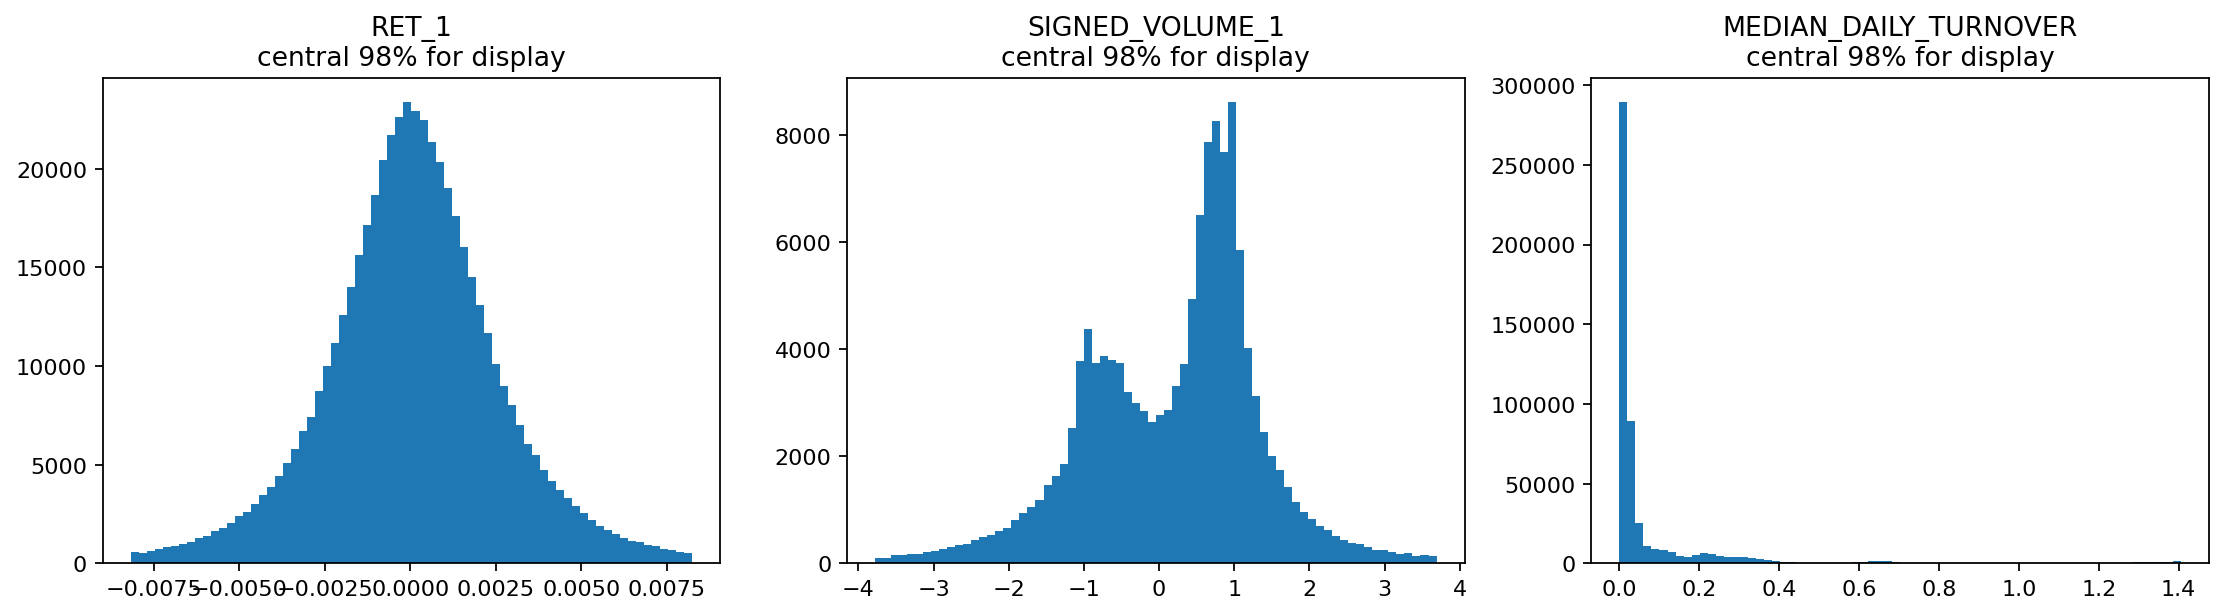

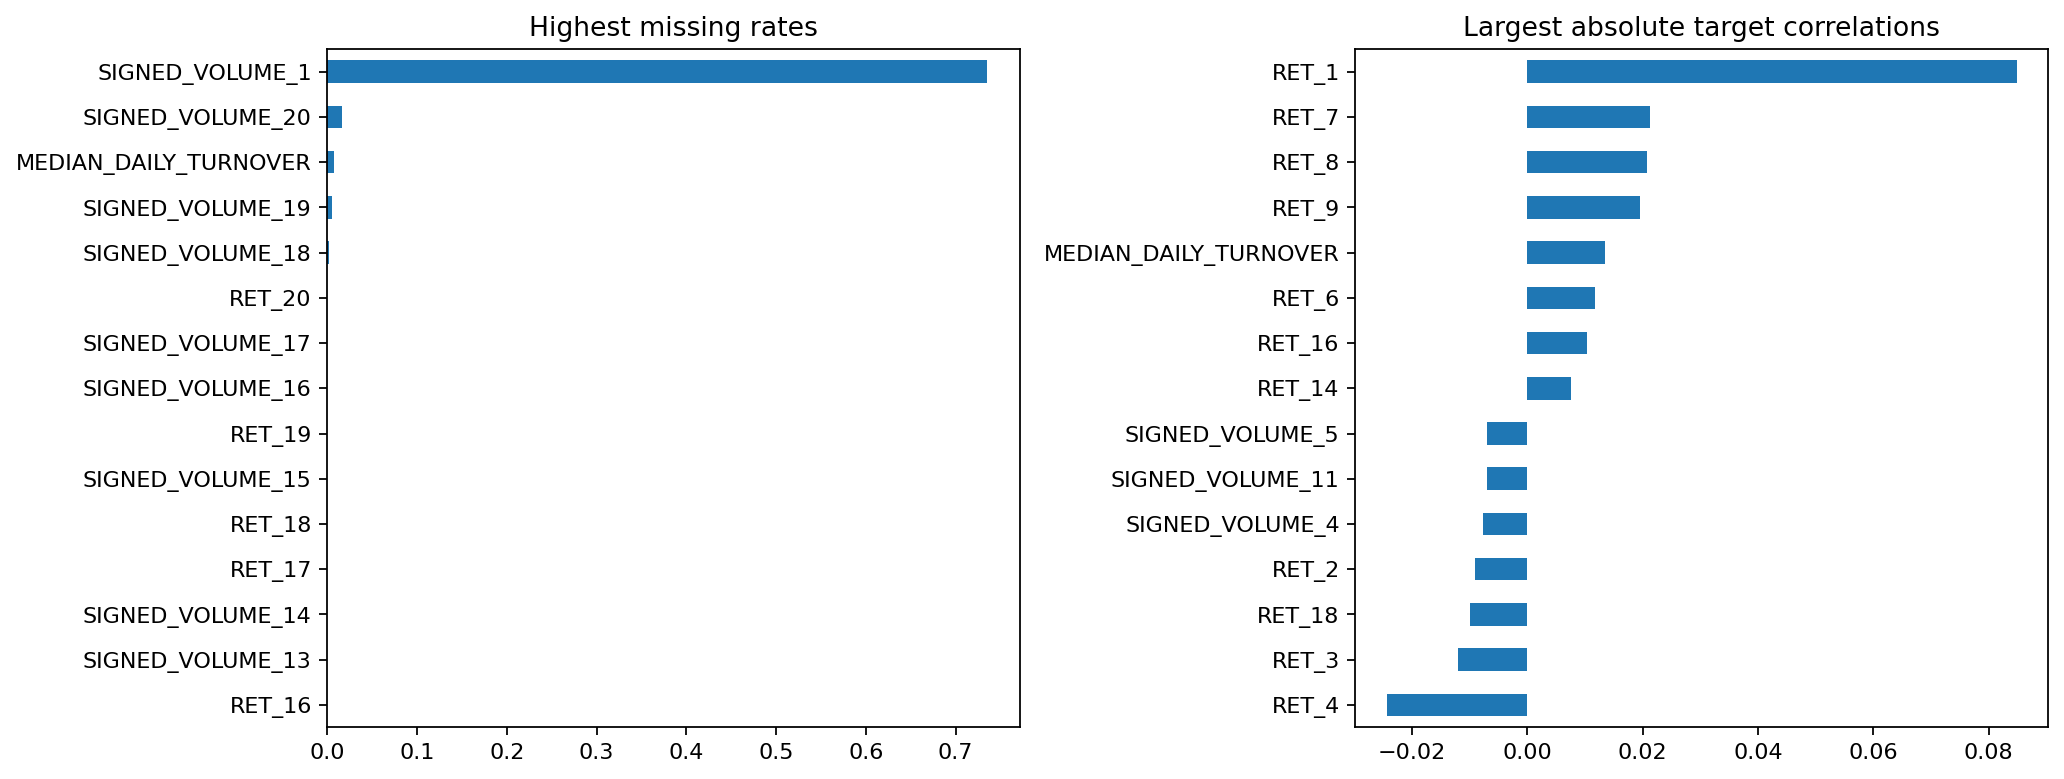

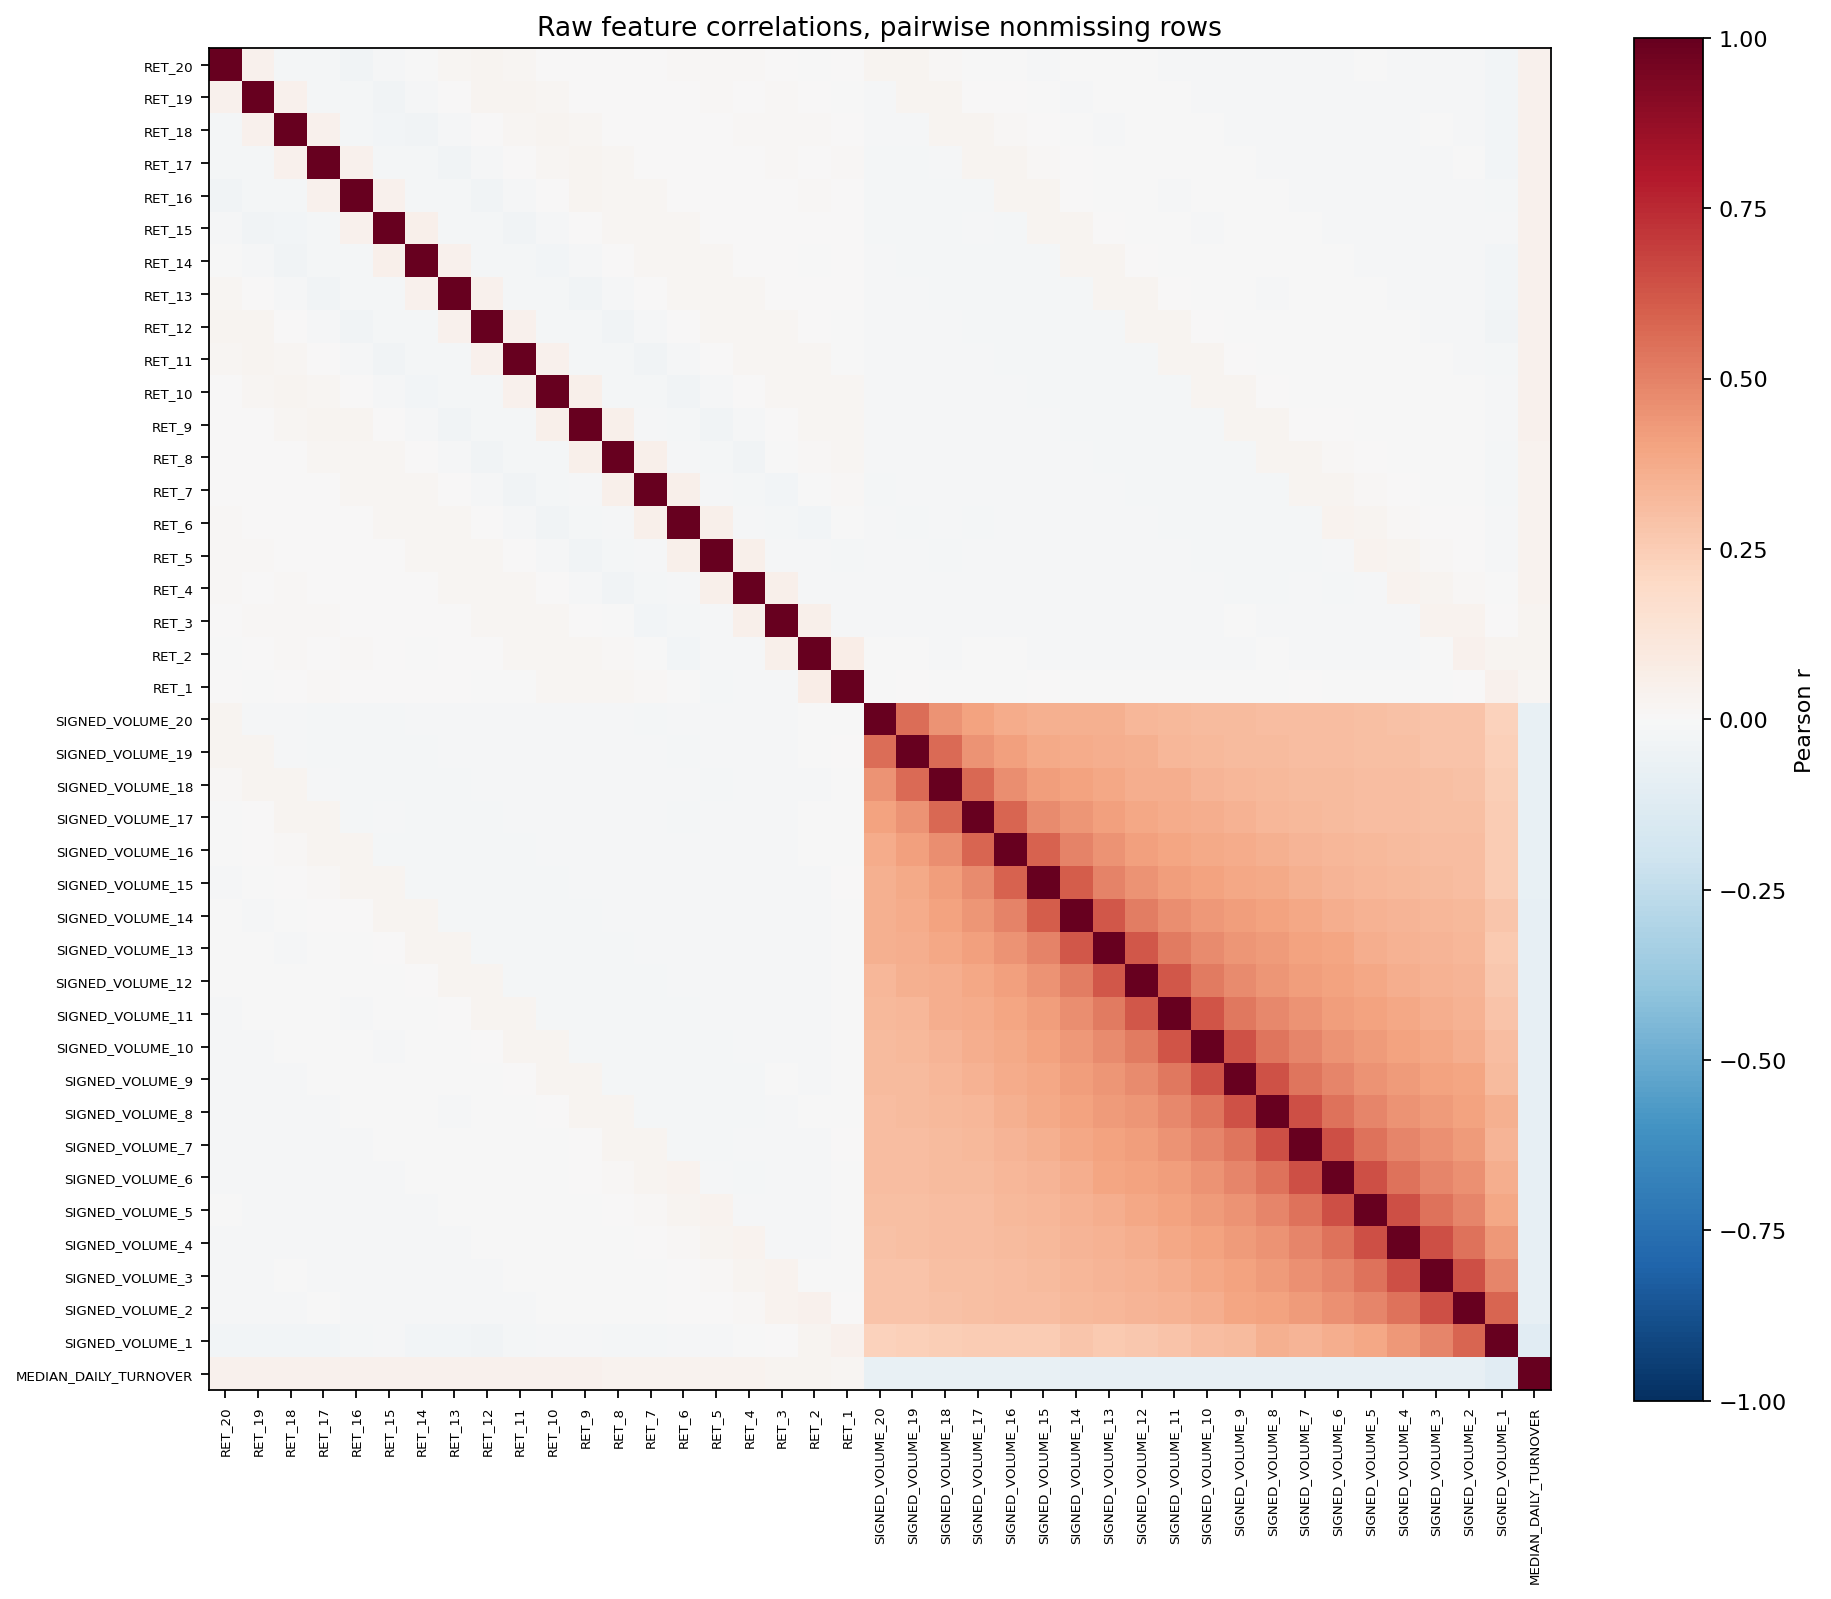

## Model structure and assumptions

```text
Statistics and volume and price characteristics → Cluster CatBoost → Allocation residual ┐
                                                    ├→ Separate standardization → Allocation fusion
Historical sequence → Global + Group joint GRU → Cluster residual ┘
```

The shared model tests for commonalities, and local correction tests for differences between objects. Cluster is a statistical similarity grouping of allocation features. GRU's global backbone and group residuals are jointly trained. The output after closing the group branch is not equivalent to retraining a pure global model.

## CatBoost structure comparison

The higher the accuracy of the form, the better. Shows all existing results structurally; rows missing OOF are left empty. The same trained base/final can be used for branch comparison, and different directories may also change features or training conditions.

In [3]:
def structure_table(family):
    table = architecture.loc[architecture.family.eq(family), ["structure", "accuracy", "kind"]].copy()
    table.columns = ["Architecture", "OOF accuracy", "Comparison type"]
    display(table.style.format({"OOF accuracy": "{:.4%}"}, na_rep="OOF unavailable"))
structure_table("CatBoost")

,Architecture,OOF accuracy,Comparison type
0,Global standalone,52.1710%,Historical architecture comparison
1,Global base (paired),52.0524%,Paired branch comparison
2,Global + group residual (paired),51.8382%,Paired branch comparison
3,Global regression base v2,52.0349%,Paired branch comparison
4,Global + group residual v2,51.7591%,Paired branch comparison
5,Allocation independent,51.6166%,Historical architecture comparison
6,Allocation + shape,51.6676%,Historical architecture comparison
7,Group base,OOF unavailable,Saved OOF unavailable
8,Group + allocation residual,OOF unavailable,Saved OOF unavailable
9,Cluster base,52.1719%,Paired branch comparison


CatBoost's global + group residuals dropped in both corresponding experiments, and the cluster + allocation residuals also dropped slightly. It cannot be claimed from this that increasing the residuals always works; but components may have different roles in the fusion.

## GRU structure comparison

The global head of the final basic model is 52.4404%, 52.5743% when including the group branch, and 52.6701% after adding the outer cluster residual. This is a layer-by-layer comparison on the saved output.

In [4]:
structure_table("GRU")

,Architecture,OOF accuracy,Comparison type
11,Group independent (seed42),52.2635%,Historical architecture comparison
12,Global head (group model),52.3550%,Paired branch comparison
13,Global + group residual,52.4846%,Paired branch comparison
14,Global head (final base run),52.4404%,Paired branch comparison
15,Global + group (final base run),52.5743%,Paired branch comparison
16,Global + group + cluster residual,52.6701%,Historical architecture comparison
17,Group base,OOF unavailable,Saved OOF unavailable
18,Group + allocation residual,OOF unavailable,Saved OOF unavailable
19,Cluster base v3,50.5655%,Paired branch comparison
20,Cluster + allocation residual v3,50.6376%,Paired branch comparison


## Fusion strategy

First normalize the two model families’ OOF scores and then compare the fusion strategies. Normalization changes the zero threshold, so here the single-model values ​​differ from the original scores. The same OOF is used for weight selection and evaluation. The following are the results after weight adjustment, not independent test scores.

In [5]:
structure_table("Combined")
sweep = read_table("global_weight_sweep.csv")
display(sweep.rename(columns={"gru_weight": "Global GRU weight", "accuracy": "OOF accuracy"}).style.format({"OOF accuracy": "{:.4%}"}))

,Architecture,OOF accuracy,Comparison type
21,CatBoost final zscore,52.0304%,Blend comparison on the same OOF
22,GRU final zscore,52.6426%,Blend comparison on the same OOF
23,Cluster linear blend,52.5115%,Blend comparison on the same OOF
24,Allocation linear blend,52.8356%,Blend comparison on the same OOF


,Global GRU weight,OOF accuracy
0,0.000000,52.0304%
1,0.050000,52.0966%
2,0.100000,52.1850%
3,0.150000,52.2301%
4,0.200000,52.3036%
5,0.250000,52.3563%
6,0.300000,52.3952%
7,0.350000,52.4535%
8,0.400000,52.5098%


## Fixed component ablation of the final model

The full model accuracy is 52.8356%. The table below closes one component and compares the remaining predictions to the full model. A negative change represents a drop in points, and the unit is percentage points; this test does not retrain, nor does it re-optimize allocation weights. Recompute the path's zscore when turning off residuals.

In [6]:
labels = {"Full allocation blend": "Full model", "Remove CatBoost residual": "Remove CatBoost residual", "Remove GRU residual": "Remove GRU outer residual", "Remove both residuals": "Remove both outer residuals", "Remove CatBoost branch": "Remove CatBoost", "Remove GRU branch": "Remove GRU", "Equal weights": "Equal-weight blend", "Cluster weights": "Cluster weights", "Global tuned weight": "Globally tuned weight"}
table = ablation[["variant", "accuracy", "delta_pp"]].copy()
table["variant"] = table.variant.map(labels)
table.columns = ["Configuration", "Accuracy", "Change (pp)"]
display(table.style.format({"Accuracy": "{:.4%}", "Change (pp)": "{:+.4f}"}))

,Configuration,Accuracy,Change (pp)
0,Full model,52.8356%,+0.0000
1,Remove CatBoost residual,52.4246%,-0.4109
2,Remove GRU outer residual,52.6236%,-0.2119
3,Remove both outer residuals,52.3963%,-0.4392
4,Remove CatBoost,52.6426%,-0.1930
5,Remove GRU,52.0304%,-0.8052
6,Equal-weight blend,52.5758%,-0.2597
7,Cluster weights,52.5115%,-0.3241
8,Globally tuned weight,52.5098%,-0.3258


The CatBoost residual single model slightly dropped the score, but it contributed to the fixed final fusion, indicating that the value of the combination cannot be judged only by the accuracy of a single model. The following uses a bar chart to directly display the accuracy, and separates removing components from changing weights.

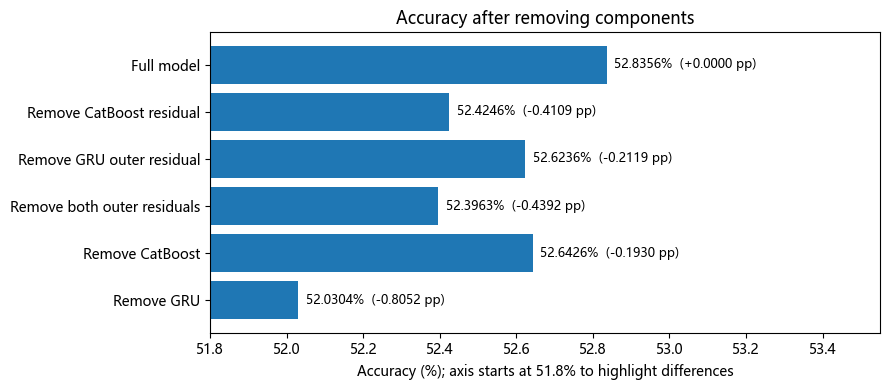

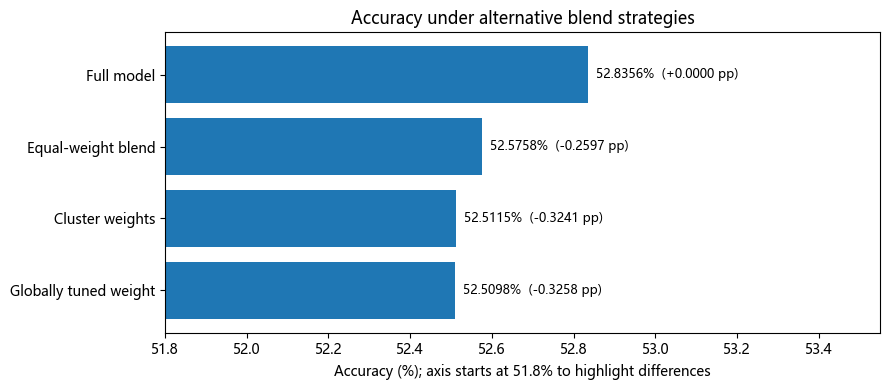

In [7]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
fonts = {f.name for f in font_manager.fontManager.ttflist}
font = next((f for f in ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "Arial Unicode MS"] if f in fonts), "DejaVu Sans")
plt.rcParams["font.sans-serif"] = [font]
plt.rcParams["axes.unicode_minus"] = False
for title, names in [("Accuracy after removing components", list(labels)[:6]), ("Accuracy under alternative blend strategies", ["Full allocation blend", "Equal weights", "Cluster weights", "Global tuned weight"])]:
    part = ablation.set_index("variant").loc[names]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh([labels[n] for n in names], part.accuracy * 100)
    for i, (value, delta) in enumerate(zip(part.accuracy, part.delta_pp)):
        ax.text(value * 100 + .02, i, f"{value:.4%}  ({delta:+.4f} pp)", va="center", fontsize=9)
    ax.set_xlim(51.8, 53.55)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Accuracy (%); axis starts at 51.8% to highlight differences")
    plt.tight_layout()
    plt.show()

### How to calculate the interval

The intervals in the original ablation results were resampled with the complete TS group: 2522 TS were extracted with replacement each time, and the paired accuracy difference between ablation and complete prediction was calculated, repeated 1000 times, and the 2.5% and 97.5% quantiles were taken. It does not include the uncertainty introduced by retraining, rebalancing, or dependencies on neighboring TSs.

## Feature importance and training indicators

Importance plot from average PredictionValuesChange of 75 CatBoost master models. Longer bars indicate greater contribution within the model and do not mean a decrease in accuracy after removing features. The Checkpoint box plot represents the distribution of selected model indicators for each fold and seed, not the training process; the lower the loss, the better.

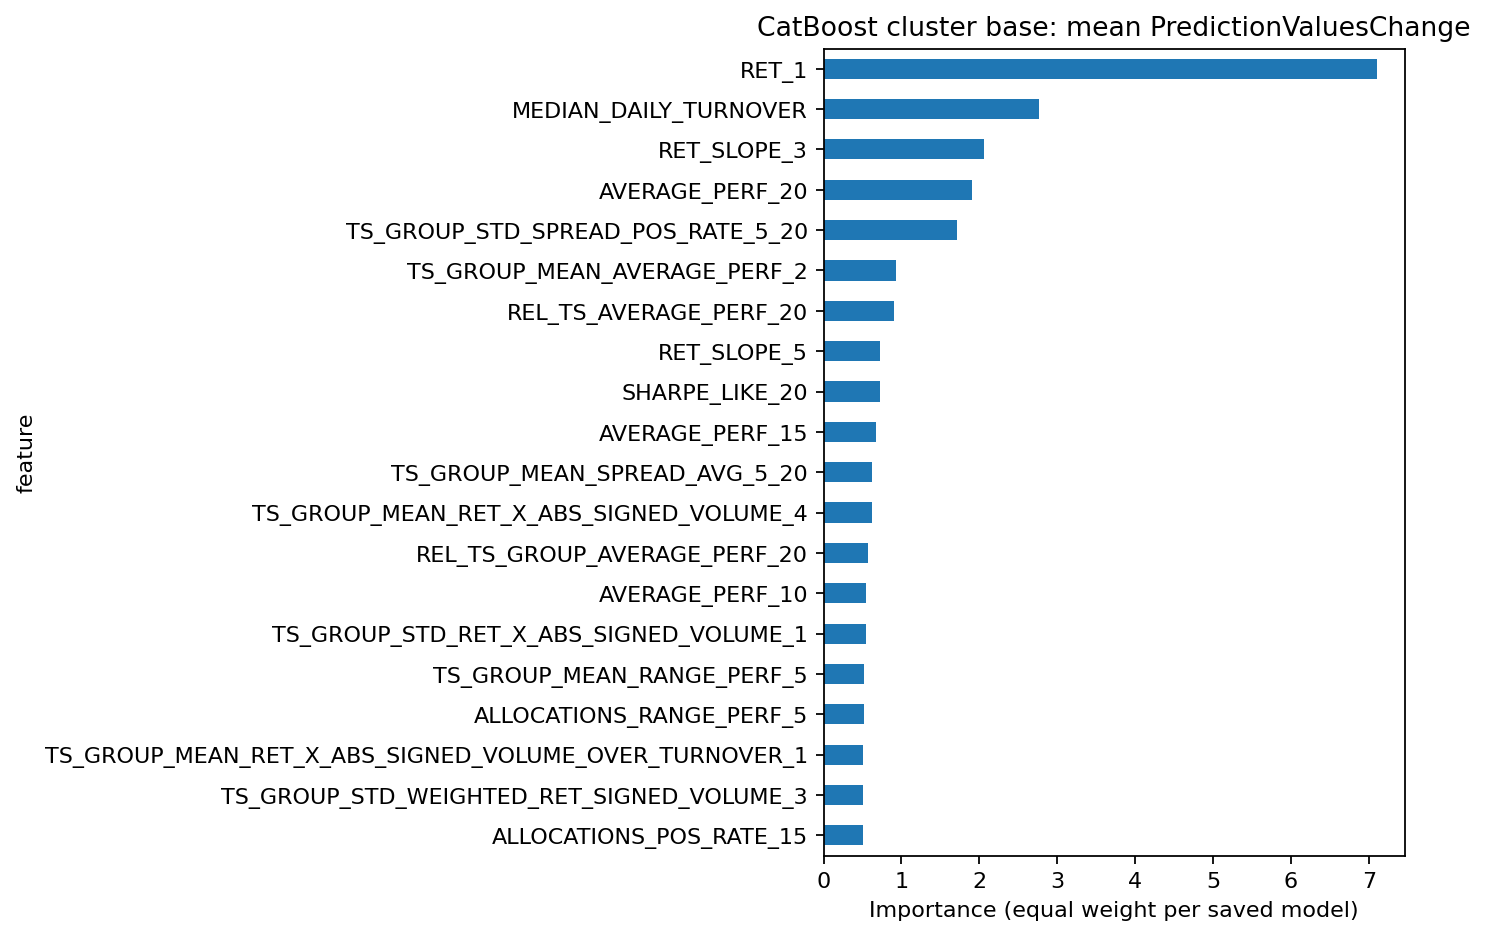

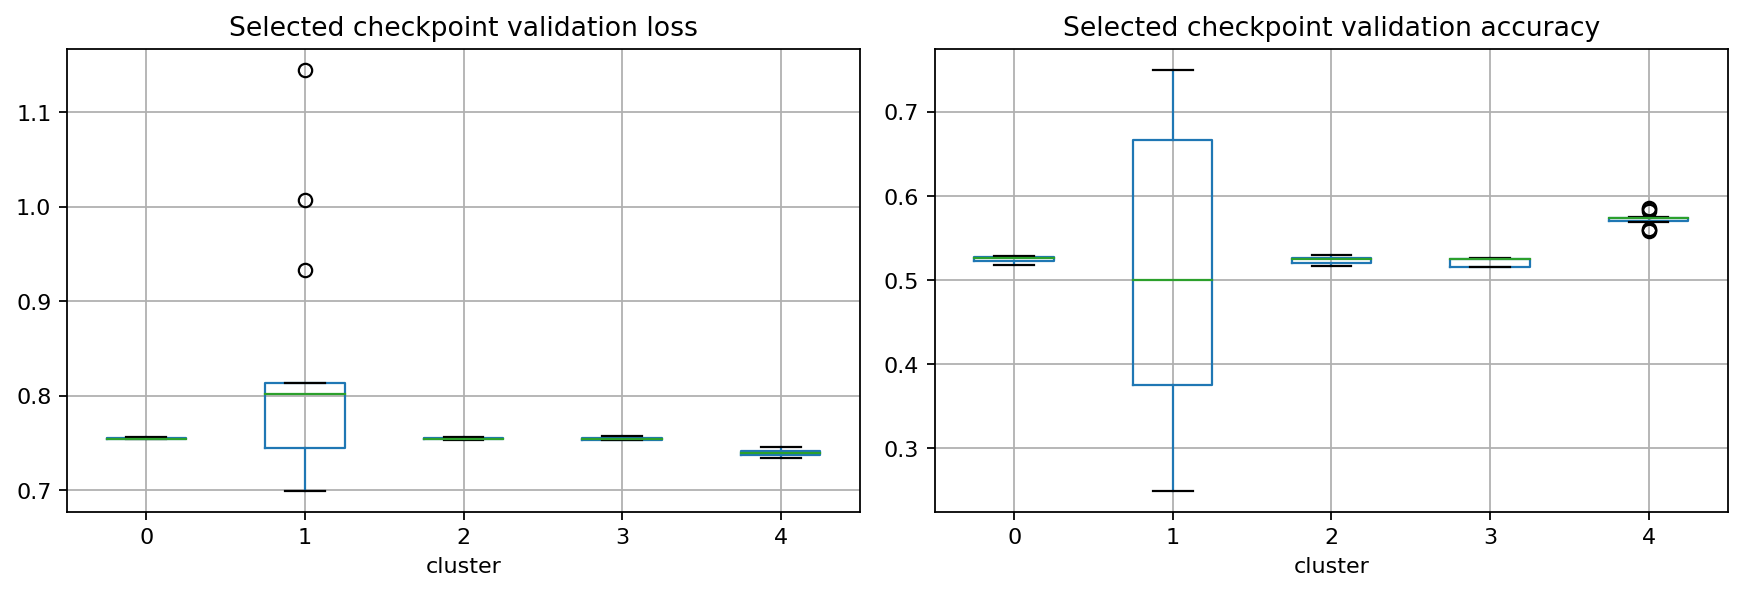

## Conclusion and scope of application

The residual effect depends on the model and level, and the contribution of the combined model may also be different from the single model effect. Allocation fusion has the highest weight adjustment OOF in the archive line, but its generalization needs to be independently verified. The existing training verification includes staggered TS points, which cannot be used to predict the future using only the past; the direction accuracy cannot be used to derive trading returns.

The epoch-by-epoch loss history is not saved, so this notebook does not draw a fictitious training decline curve. Analysis tables and figures can be recalculated from existing data and models, and re-execution of complete training has not yet been verified. See [summary.md](summary.md) for the main explanation.